# SPECTRA tutorial 2: group statistics and synthetic effect injection

This notebook runs statistical analysis in Python, using the same classes that the `spectra_lmm_fdr` CLI calls. It runs on `sample_data/stats/`: 2D FA profiles of three bundles (AF_L, CST_L, CC_ForcepsMajor) for 64 subjects (32 controls, 32 patients) from the DIPY-processed PPMI derivatives. The `age`, `sex` and `site` columns of the metadata table are simulated for this demo.

**Part 1** compares patients with controls: fit a model at every grid cell, then correct for multiple comparisons with BH-FDR and with hierarchical FDR (hFDR). The sample data shows no significant difference.

**Part 2** injects a known effect into half of the subjects and runs the same analysis again, to show what a detection looks like and how it is scored against the ground truth. This is the procedure behind the paper's synthetic experiments.

Model fitting uses [`pymer4`](https://github.com/ejolly/pymer4), which needs R (see the installation section of the [README](../README.md)).

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from spectra.tractometry.BundleProfileLoader import BundleProfileLoader
from spectra.tractometry.MultiBundleLM import MultiBundleLM
from spectra.tractometry.results_data import get_stat_map, get_sig_map
from spectra.simulation.evaluation import evaluate_synthetic_results
from spectra.viz.viz_grid import plot_stats_map, plot_significance, plot_checkerboard
from spectra.utils.io import load_list
from spectra.utils.utils import setup_logging

setup_logging()

## Part 1: patients vs. controls

### 1.1 Load the profiles and metadata

`BundleProfileLoader` reads the profiles from `<root_dir>/<metric>/<bundle>/<subject>.npz`, matches them to the rows of the metadata table, and holds the model settings: the variable to test (`dx`, patient vs. control) and the covariates.

In [5]:
DATA_DIR = Path('../sample_data/stats')
OUT_DIR  = DATA_DIR / 'outputs' / 'tutorial'

metadata = pd.read_csv(DATA_DIR / 'metadata.csv', dtype={'subject': str})
bundles  = load_list(str(DATA_DIR / 'bundle_list.txt'))

loader = BundleProfileLoader(
    metadata_df=metadata,
    bundles=bundles,
    metric='fa',
    root_dir=str(DATA_DIR),
    mode='2d',                      # '1d' for along-tract profiles
    target_col='dx',
    target_ref_group='control',
    target_case_group='patient',
    covar_cols=['age', 'sex'],
    cont_cols=['age'],
    group_col=None,
    disable_tqdm=True,
)

print('Bundles: ', bundles)
print('Subjects:', loader.n_subjects)
metadata.head()

2026-10-11 16:29:52,641 [INFO] [root:BundleProfileLoader._filter_metadata]: Filtered metadata: 64 -> 64 rows (required cols: ['dx', 'subject', 'age', 'sex'])
Bundles:  ['AF_L', 'CST_L', 'CC_ForcepsMajor']
2026-10-11 16:29:52,643 [INFO] [root:BundleProfileLoader.subjects_by_bundle]: Subjects with a profile and metadata: AF_L=64, CST_L=64, CC_ForcepsMajor=64
Subjects: 64


,subject,dx,age,sex,site
0,3109,control,63.0,M,site2
1,3151,control,60.9,F,site1
2,3161,control,67.1,M,site3
3,3165,control,62.8,M,site4
4,3169,control,57.7,M,site2


### 1.2 Fit the model and apply hFDR

`MultiBundleLM` fits `FA ~ dx + age + sex` at every grid cell of every bundle. With `group_col=None` this is an ordinary linear regression, which takes a few seconds per bundle. Setting `group_col='site'` (here and in the loader) adds a random intercept per site, as in the README example; that fits a mixed model at every cell and takes a few minutes per bundle.

`fit_hierarchical_fdr` fits the models and then corrects in two stages:
- **Stage 1** divides each bundle into blocks whose size follows the spatial correlation of the data (RESEL blocks), combines the cell p-values of each block, and applies BH-FDR across blocks at `alpha_block`.
- **Stage 2** tests the cells inside each significant block at `alpha_cell`.

`save=True` stores the fitted statistics in `output_dir`, so other corrections can be applied without fitting again.

In [6]:
lmm = MultiBundleLM(
    dataloader=loader,
    s_len=5, r_len=5,               # grid cell size (mm) used for the profiles
    group_col=None,
    disable_tqdm=True,
    output_dir=str(OUT_DIR / 'dx'),
)

hfdr = lmm.fit_hierarchical_fdr(
    alpha_block=0.05,
    alpha_cell=0.15,
    use_resel_blocks=True,
    combination_method='simes',
    save=True,
)

print(f'hFDR Stage 1: {hfdr.n_blocks_sig} of {hfdr.n_blocks} blocks significant')
print(f'hFDR Stage 2: {hfdr.n_cells_sig} cells significant')

2026-10-11 16:29:55,709 [INFO] [root:MultiBundleLM.__init__]: MultiBundleLM initialized: 3 bundles, 64 subjects, target=dx[T.patient], target_is_binary=True
2026-10-11 16:29:55,711 [INFO] [root:MultiBundleLM.__init__]: ---Groups for dx: {'control': 32, 'patient': 32}
2026-10-11 16:29:55,712 [INFO] [root:MultiBundleLM.__init__]: ---Formula: metric ~ dx + age + sex
2026-10-11 16:29:55,714 [INFO] [root:MultiBundleLM.fit_hierarchical_fdr]: Hierarchical FDR Stage 1: 3 bundles, mode=RESEL-block, combination=simes, alpha_block=0.05
2026-10-11 16:29:55,749 [INFO] [root:BundleProfileLoader.aggregate_profiles]: Aggregated 2d fa profiles for AF_L: 64 subjects, grid (24, 9)
2026-10-11 16:29:55,784 [INFO] [root:MultiBundleLM._fit_observed_single_grid]: Fitting AF_L: 64 subjects, 135 cells (grid 24 x 9)
2026-10-11 16:29:57,512 [INFO] [root:MultiBundleLM._fit_observed_single_grid]: Length scales for AF_L: along-tract 6.5 mm, radial 6.8 mm
2026-10-11 16:29:57,524 [INFO] [root:MultiBundleLM._fit_observ

For comparison, standard BH-FDR across all cells, applied to the saved fits:

In [7]:
fdr = lmm.fit_observed_fdr(alpha=0.05, from_saved=True)

df_fdr = fdr.get_stats_all()
print(f"BH-FDR: {int(df_fdr['sig_fdr'].sum())} of {len(df_fdr)} cells significant")

2026-10-11 16:30:04,699 [INFO] [root:MultiBundleLM.fit_observed_fdr]: Loaded observed results for 3 bundles
2026-10-11 16:30:04,701 [INFO] [root:results_data.apply_global_fdr]: BH-FDR (alpha=0.05): 0/465 cells significant
BH-FDR: 0 of 465 cells significant


### 1.3 Check results

`get_stats_all` returns one row per tested cell, with the test statistics (`t_obs`, `p_obs`, `beta_obs`, `d_cohen`, ...), the block the cell belongs to, and the corrected significance.

In [8]:
df_hfdr = hfdr.get_stats_all()
df_hfdr.head()

,bundle,s_idx,r_idx,ns,nr,t_obs,p_obs,beta_obs,se,dof,ci_lower,ci_upper,r2_partial,d_cohen,p_cond,p_hfdr,sig_hfdr,block_id,block_sig
0,AF_L,1,0,24,9,0.068420,0.945761,0.010542,0.154072,44.0,-0.299971,0.321054,0.000106,-0.002395,NaN,NaN,False,0,False
1,AF_L,1,1,24,9,-0.783174,0.436947,-0.097895,0.124998,54.0,-0.348500,0.152710,0.011231,-0.108286,NaN,NaN,False,0,False
2,AF_L,1,2,24,9,0.205931,0.837605,0.023015,0.111760,55.0,-0.200956,0.246986,0.000770,0.082530,NaN,NaN,False,0,False
3,AF_L,1,3,24,9,-1.156709,0.252391,-0.125550,0.108541,55.0,-0.343070,0.091970,0.023749,-0.318855,NaN,NaN,False,1,False
4,AF_L,1,4,24,9,0.122704,0.902815,0.015224,0.124072,52.0,-0.233745,0.264193,0.000289,-0.025451,NaN,NaN,False,1,False


`get_stat_map` and `get_sig_map` turn the table back into (s, r) grids for one bundle. The top row shows the Stage 1 blocks as a checkerboard, and the bottom row the Cohen's d of every tested cell (patient minus control). Cells with too few subjects are not tested and are left blank.

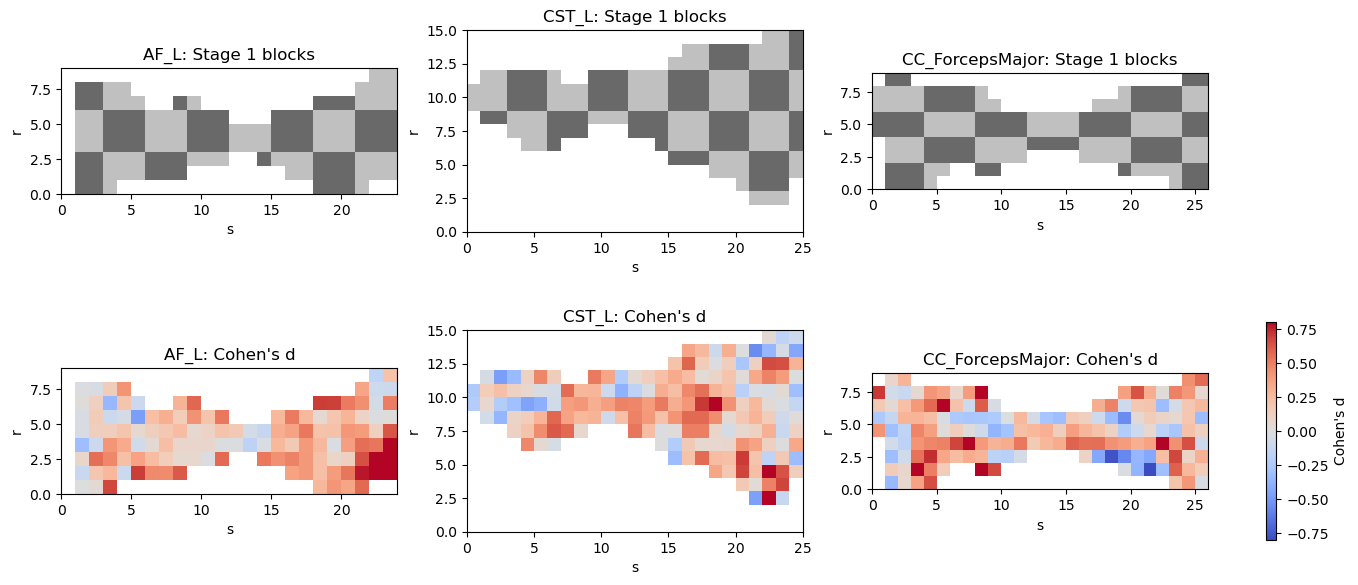

In [9]:
fig, axes = plt.subplots(2, len(bundles), figsize=(4.5 * len(bundles), 6), constrained_layout=True)

for j, bundle in enumerate(bundles):
    blocks = get_sig_map(df_hfdr, bundle)['block_grid']
    d_grid = get_stat_map(df_hfdr, bundle, 'd_cohen')

    plot_checkerboard(blocks, ax=axes[0, j], title=f'{bundle}: Stage 1 blocks')
    plot_stats_map(d_grid, ax=axes[1, j], cmap='coolwarm', vmin=-0.8, vmax=0.8, vcenter=0,
                   title=f"{bundle}: Cohen's d")

fig.colorbar(axes[1, 0].collections[0], ax=axes[1, :], label="Cohen's d", shrink=0.8)
plt.show()

No cell is significant under either correction, so there is nothing to show on a significance map. To save these grids for rendering on the 3D bundle, see `spectra_export_stats` and `spectra_viz` in the [README](../README.md).

## Part 2: synthetic effect injection

To see what the method detects when an effect is present, we add a known one to real data:

1. Split the subjects at random into two groups of 32.
2. Draw an effect map: where on the grid the effect is, and how large (in Cohen's d).
3. Add the effect to one group, scaled by the standard deviation of each cell.
4. Run the same analysis on the group label and compare the detections with the effect map.

The data keeps its real spatial correlation and missing cells, and the ground truth is known.

### 2.1 Create the effect map

In [10]:
rng = np.random.default_rng(0)
loader.reset()

# Random split: the first half receives the effect
subjects = rng.permutation(loader.subjects)
effect_subjects = subjects[:len(subjects) // 2]

# One large region per bundle with a peak effect of d = 0.8 (the paper's "diffuse" setting).
# For the "localized" setting use n_blobs=4, center_range=(0.2, 0.8), extent_range=(0.05, 0.15).
effect_maps = loader.create_effect_maps(
    n_blobs=1,
    center_range=(0.3, 0.7),        # where the region is centered (fraction of the grid)
    extent_range=(0.3, 0.5),        # how far it extends (fraction of the grid)
    max_effect_range=(0.8, 0.8),    # peak Cohen's d
    min_effect=0.1,
    decay='cosine',
    geometry='ellipse',
    s_len=5, r_len=5,
    rng=rng,
)

# Put the effect in one bundle only; the other two have no effect
AFFECTED = 'CST_L'
for bundle in bundles:
    if bundle != AFFECTED:
        effect_maps[bundle] = np.zeros_like(effect_maps[bundle])

2026-10-11 16:31:21,800 [INFO] [root:BundleProfileLoader._filter_metadata]: Filtered metadata: 64 -> 64 rows (required cols: ['dx', 'subject', 'age', 'sex'])


### 2.2 Inject the effect

`inject_synthetic_effect` adds `effect_map × SD` to the profiles of the chosen subjects, at cells where a subject has data (missing cells stay missing). It also adds a 0/1 column to the metadata, which becomes the variable to test, and returns the Cohen's d actually realized at each cell.

In [11]:
d_maps = loader.inject_synthetic_effect(
    effect_maps=effect_maps,
    effect_size=1.0,                # the effect maps are already in Cohen's d units
    effect_subjects=effect_subjects,
    effect_col_name='synthetic_group',
)

loader.get_metadata()['synthetic_group'].value_counts()

2026-10-11 16:31:34,368 [INFO] [root:BundleProfileLoader.inject_synthetic_effect]: Injected effect (d=1.0) to 32 subjects across 3 bundles


numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


synthetic_group
1    32
0    32
Name: count, dtype: int64

### 2.3 Run the same analysis on the injected data

The only change from Part 1 is the variable to test: `synthetic_group` (1 vs. 0) instead of `dx`.

In [12]:
lmm_synth = MultiBundleLM(
    dataloader=loader,
    s_len=5, r_len=5,
    group_col=None,
    target_col='synthetic_group',
    target_ref_group=0,
    target_case_group=1,
    covar_cols=['age', 'sex'],
    disable_tqdm=True,
    output_dir=str(OUT_DIR / 'synthetic'),
)

hfdr_synth = lmm_synth.fit_hierarchical_fdr(
    alpha_block=0.05, alpha_cell=0.15,
    use_resel_blocks=True, combination_method='simes',
    save=True,
)
fdr_synth = lmm_synth.fit_observed_fdr(alpha=0.05, from_saved=True)

df_hfdr_synth = hfdr_synth.get_stats_all()
df_fdr_synth  = fdr_synth.get_stats_all()

print(f'hFDR Stage 1: {hfdr_synth.n_blocks_sig} of {hfdr_synth.n_blocks} blocks significant')
print(f'hFDR Stage 2: {hfdr_synth.n_cells_sig} cells significant')
print(f"BH-FDR:       {int(df_fdr_synth['sig_fdr'].sum())} of {len(df_fdr_synth)} cells significant")

2026-10-11 16:31:44,236 [INFO] [root:MultiBundleLM.__init__]: MultiBundleLM initialized: 3 bundles, 64 subjects, target=synthetic_group[T.1], target_is_binary=True
2026-10-11 16:31:44,237 [INFO] [root:MultiBundleLM.__init__]: ---Groups for synthetic_group: {1: 32, 0: 32}
2026-10-11 16:31:44,237 [INFO] [root:MultiBundleLM.__init__]: ---Formula: metric ~ synthetic_group + age + sex
2026-10-11 16:31:44,237 [INFO] [root:MultiBundleLM.fit_hierarchical_fdr]: Hierarchical FDR Stage 1: 3 bundles, mode=RESEL-block, combination=simes, alpha_block=0.05
2026-10-11 16:31:44,281 [INFO] [root:MultiBundleLM._fit_observed_single_grid]: Fitting AF_L: 64 subjects, 135 cells (grid 24 x 9)
2026-10-11 16:31:45,970 [INFO] [root:MultiBundleLM._fit_observed_single_grid]: Length scales for AF_L: along-tract 6.5 mm, radial 6.8 mm
2026-10-11 16:31:45,982 [INFO] [root:MultiBundleLM._fit_observed_single_grid]: Saved observed results: ../sample_data/stats/outputs/tutorial/synthetic/observed/AF_L.npz
2026-10-11 16:31

### 2.4 Compare the detections with the injected effect

For the affected bundle, from left to right: the injected effect map, the Cohen's d estimated from the data, and the cells declared significant by hFDR and by BH-FDR.

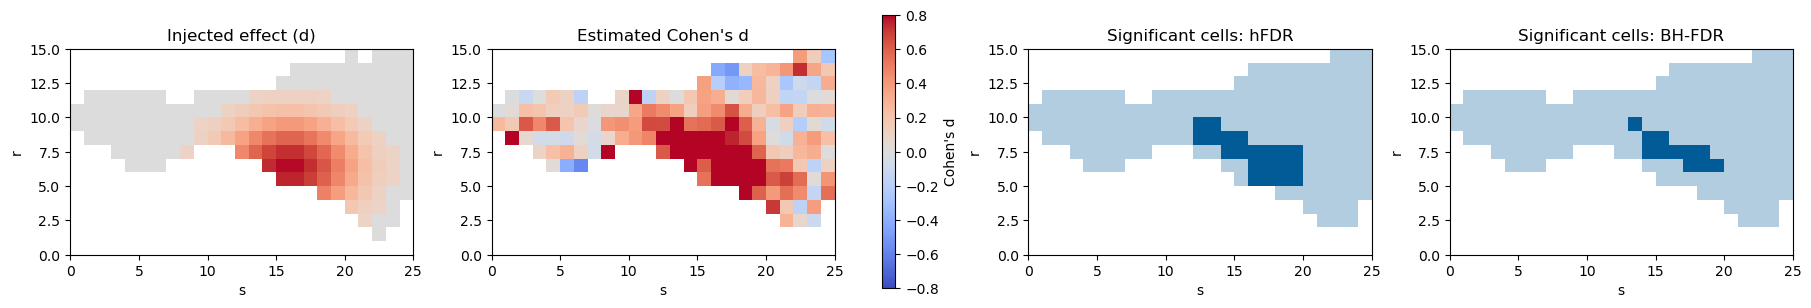

In [13]:
ns, nr, mask = loader.get_grid_info(AFFECTED)

injected  = np.where(mask, effect_maps[AFFECTED], np.nan)
estimated = get_stat_map(df_hfdr_synth, AFFECTED, 'd_cohen')
sig_hfdr  = get_sig_map(df_hfdr_synth, AFFECTED)['sig_grid_cell']
sig_fdr   = get_sig_map(df_fdr_synth, AFFECTED, is_hfdr=False)['sig_grid_cell']

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5), constrained_layout=True)
plot_stats_map(injected,  ax=axes[0], cmap='coolwarm', vmin=-0.8, vmax=0.8, vcenter=0, title='Injected effect (d)')
plot_stats_map(estimated, ax=axes[1], cmap='coolwarm', vmin=-0.8, vmax=0.8, vcenter=0, title="Estimated Cohen's d")
plot_significance(sig_hfdr, ax=axes[2], title='Significant cells: hFDR')
plot_significance(sig_fdr,  ax=axes[3], title='Significant cells: BH-FDR')
fig.colorbar(axes[1].collections[0], ax=axes[:2], label="Cohen's d", shrink=0.8)
plt.show()

`evaluate_synthetic_results` scores the detections cell by cell against the effect map: a cell with a non-zero injected effect is a true effect. `recall` is the sensitivity, and `1 - precision` is the false discovery proportion.

In [14]:
cols = ['bundle', 'TP', 'FP', 'FN', 'TN', 'precision', 'recall']

scores = pd.concat([
    evaluate_synthetic_results(hfdr_synth, effect_maps, d_maps)[cols].assign(method='hFDR'),
    evaluate_synthetic_results(fdr_synth,  effect_maps, d_maps)[cols].assign(method='BH-FDR'),
])
scores[scores['bundle'] == 'GLOBAL'].set_index('method').drop(columns='bundle')

,TP,FP,FN,TN,precision,recall
method,,,,,,
hFDR,20,0,64,381,1.000000,0.238095
BH-FDR,11,1,73,380,0.916667,0.130952


This is a single run with 32 subjects per group, so the numbers vary with the random split and the effect map (change the seed in 2.1 to see this). The paper repeats this procedure 100 times for each combination of effect size, sample size, number of affected bundles and effect pattern; the scripts are in [`paper/`](../paper/instructions.md) (`02a_synth_eval.py`), and the injection code is in [`src/spectra/simulation/`](../src/spectra/simulation/).